# Face + hand landmarks (MediaPipe Tasks API)

Originally this notebook drove MediaPipe's `solutions.FaceMesh` / `solutions.Hands`. As of mediapipe 0.10+ the `mp.solutions` namespace is gone in favor of the Tasks API (`mediapipe.tasks.vision.FaceLandmarker` / `HandLandmarker`), which needs a `.task` model bundle. This version uses the Tasks API with Google's published model bundles (about 11MB for both), downloaded on first run.

Images: real photos from HaGRID (HAnd Gesture Recognition Image Dataset, Kapitanov et al., CC BY-SA 4.0), via the `cj-mills/hagrid-sample-30k-384p` sample on Hugging Face. Every HaGRID photo shows a person making a hand gesture toward the camera, so each one should contain at least one hand and usually a face. I read one parquet row group and use the first 40 images.

HaGRID ships gesture labels and hand boxes but not keypoints, and the boxes aren't in this parquet, so I can't score landmark accuracy here. What I can measure is how often each detector finds anything at all.

In [1]:
# !pip install mediapipe opencv-python -q
import io, urllib.request
import cv2, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
import pyarrow.parquet as pq
from huggingface_hub import HfFileSystem
from PIL import Image
import mediapipe as mp
from mediapipe.tasks import python as mp_tasks
from mediapipe.tasks.python import vision

MODELS = Path("../../data/mediapipe_models"); MODELS.mkdir(parents=True, exist_ok=True)
ART = Path("artifacts"); ART.mkdir(exist_ok=True)
BUNDLES = {
    "face_landmarker.task": "https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task",
    "hand_landmarker.task": "https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task",
}
for name, url in BUNDLES.items():
    if not (MODELS / name).exists():
        urllib.request.urlretrieve(url, MODELS / name)
print(sorted(p.name for p in MODELS.iterdir()))

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/google/api_core/_python_version_support.py:266: FutureWarning: You are using a Python version (3.11.9) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


['face_landmarker.task', 'hand_landmarker.task']


In [2]:
fs = HfFileSystem()
pf = pq.ParquetFile(fs.open("datasets/cj-mills/hagrid-sample-30k-384p@refs%2Fconvert%2Fparquet/default/train/0000.parquet"))
rows = pf.read_row_group(0).to_pylist()[:40]
images = [np.asarray(Image.open(io.BytesIO(r["image"]["bytes"])).convert("RGB")) for r in rows]
print(len(images), "real photos, e.g. size", images[0].shape)

40 real photos, e.g. size (512, 384, 3)


## Run both landmarkers

In [3]:
face_det = vision.FaceLandmarker.create_from_options(vision.FaceLandmarkerOptions(
    base_options=mp_tasks.BaseOptions(model_asset_path=str(MODELS / "face_landmarker.task")), num_faces=2))
hand_det = vision.HandLandmarker.create_from_options(vision.HandLandmarkerOptions(
    base_options=mp_tasks.BaseOptions(model_asset_path=str(MODELS / "hand_landmarker.task")), num_hands=2))

results = []
for img in images:
    mp_img = mp.Image(image_format=mp.ImageFormat.SRGB, data=np.ascontiguousarray(img))
    results.append((face_det.detect(mp_img), hand_det.detect(mp_img)))

n_face = sum(len(f.face_landmarks) > 0 for f, _ in results)
n_hand = sum(len(h.hand_landmarks) > 0 for _, h in results)
print(f"images with a face found: {n_face}/{len(images)}")
print(f"images with a hand found: {n_hand}/{len(images)}")
print("points per face:", len(results[0][0].face_landmarks[0]) if results[0][0].face_landmarks else "n/a",
      "| points per hand: 21")

I0000 00:00:1795036535.600817 15046255 init-domain.cc:128] Fiber init: default domain = pthread, concurrency = 8, prefix = pthread-default
W0000 00:00:1795036535.601414 15046255 face_landmarker_graph.cc:180] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
I0000 00:00:1795036535.768205 15046255 gl_context.cc:407] GL version: 2.1 (2.1 Metal - 89.3), renderer: Apple M2
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1795036535.770275 15046258 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795036535.778376 15046258 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
I0000 00:00:1795036535.783629 15046269 gl_context.cc:407] GL version: 2.1 (2.1 Metal - 89.3), renderer: Apple M2
W0000 00:00:1795036535.787899 15046276 inference_feedback_manager.cc:121] Feedback

W0000 00:00:1795036535.832532 15046272 landmark_projection_calculator.cc:81] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.


images with a face found: 33/40
images with a hand found: 37/40
points per face: 478 | points per hand: 21


## Overlay

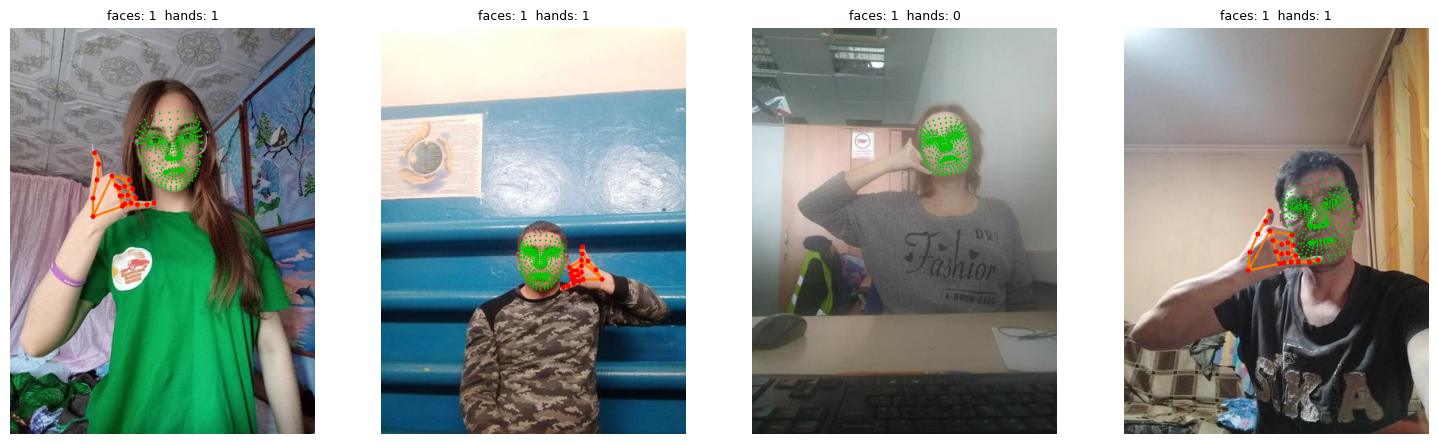

In [4]:
HAND_CONNECTIONS = [(0,1),(1,2),(2,3),(3,4),(0,5),(5,6),(6,7),(7,8),(5,9),(9,10),(10,11),(11,12),
                    (9,13),(13,14),(14,15),(15,16),(13,17),(0,17),(17,18),(18,19),(19,20)]

def overlay(img, face_res, hand_res):
    out = img.copy(); H, W = out.shape[:2]
    for face in face_res.face_landmarks:
        for lm in face:
            cv2.circle(out, (int(lm.x * W), int(lm.y * H)), 1, (0, 200, 0), -1)
    for hand in hand_res.hand_landmarks:
        pts = [(int(lm.x * W), int(lm.y * H)) for lm in hand]
        for a, b in HAND_CONNECTIONS:
            cv2.line(out, pts[a], pts[b], (255, 120, 0), 2)
        for p in pts:
            cv2.circle(out, p, 3, (255, 0, 0), -1)
    return out

fig, ax = plt.subplots(1, 4, figsize=(15, 4.5))
for a, i in zip(ax, range(4)):
    f, h = results[i]
    a.imshow(overlay(images[i], f, h)); a.axis("off")
    a.set_title(f"faces: {len(f.face_landmarks)}  hands: {len(h.hand_landmarks)}", fontsize=9)
plt.tight_layout(); plt.savefig(ART / "landmarks.png", dpi=110); plt.show()

## Notes

On 40 real HaGRID photos, the face landmarker (478 points per face) found a face in 33 and the hand landmarker (21 points per hand) found a hand in 37. Every photo has a gesturing hand, so 3 misses on hands is a real miss rate of about 8% on this small sample. In the overlay above, the third photo is a miss: the hand held up next to the face (HaGRID's "call" gesture) isn't detected, which looks like the hardest case for the hand model, since part of the hand overlaps the face and hair. Faces get missed more often, though I haven't checked whether those photos even show a full face, since some HaGRID shots are cropped or taken from far away.

What I'd do to make this a real evaluation: pull HaGRID's hand boxes (they're in the full dataset annotations) and score hand detection with IoU, and use a face dataset with landmark labels (300W or WFLW) to measure landmark error in pixels normalized by eye distance.

The downstream consumers (drawing keypoints, computing distances for blink / gaze / gesture rules) just need the normalized `(x, y, z)` points the Tasks API returns, so this cell layout carries over to video by switching the running mode to `VIDEO` and feeding frames with timestamps.